# Качество данных

Проверяем данные Elliptic: основные статистики, пропуски, ошибочные значения и выбросы.

## 1. Основные статистики

In [1]:
from bitcoin_aml_detection.data import AGG_FEATURES, FEATURES, LOCAL_FEATURES, load_edges, load_txs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = load_txs()
df.shape

(203769, 169)

In [2]:
df.dtypes.value_counts()

float64    166
int64        2
object       1
Name: count, dtype: int64

In [3]:
df.head()

,txId,time_step,local_1,local_2,local_3,local_4,local_5,local_6,local_7,local_8,...,agg_65,agg_66,agg_67,agg_68,agg_69,agg_70,agg_71,agg_72,label,y
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,unknown,NaN
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,unknown,NaN
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,unknown,NaN
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,licit,0.0
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,unknown,NaN


In [4]:
df.describe(include="all").round(4)

,txId,time_step,local_1,local_2,local_3,local_4,local_5,local_6,local_7,local_8,...,agg_65,agg_66,agg_67,agg_68,agg_69,agg_70,agg_71,agg_72,label,y
count,2.037690e+05,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,...,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,203769.0000,203769,46564.0000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unknown,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,157205,NaN
mean,1.711310e+08,23.8440,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,-0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.0976
std,1.104655e+08,15.1722,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,...,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,NaN,0.2968
min,1.076000e+03,1.0000,-0.1730,-0.2106,-1.7564,-0.1220,-0.0637,-0.1130,-0.0616,-0.1636,...,-0.9791,-0.9786,-0.2161,-0.1259,-0.1312,-0.2698,-1.7609,-1.7610,NaN,0.0000
25%,8.433452e+07,9.0000,-0.1725,-0.1803,-1.2014,-0.1220,-0.0439,-0.1130,-0.0616,-0.1635,...,-0.9791,-0.9786,-0.0989,-0.0875,-0.1312,-0.1406,-0.1206,-0.1198,NaN,0.0000
50%,1.624375e+08,23.0000,-0.1692,-0.1329,0.4636,-0.1220,-0.0439,-0.1130,-0.0616,-0.1620,...,0.2411,0.2414,0.0183,-0.0875,-0.1312,-0.0975,-0.1206,-0.1198,NaN,0.0000
75%,2.454798e+08,38.0000,-0.1319,-0.0552,1.0186,-0.1220,-0.0439,-0.1130,-0.0616,-0.1356,...,1.3056,1.3988,0.0183,-0.0875,-0.0847,-0.0975,0.1520,0.1200,NaN,0.0000


In [5]:
groups = {"local": LOCAL_FEATURES, "agg": AGG_FEATURES}

pd.DataFrame({
    name: {
        "признаков": len(columns),
        "наибольший модуль среднего": df[columns].mean().abs().max(),
        "наименьший std": df[columns].std().min(),
        "типичная медиана": df[columns].median().median(),
        "типичный максимум": df[columns].max().median(),
        "самый большой максимум": df[columns].max().max(),
    }
    for name, columns in groups.items()
}).round(3)

,local,agg
признаков,93.000,72.000
наибольший модуль среднего,0.000,0.000
наименьший std,1.000,1.000
типичная медиана,-0.122,-0.090
типичный максимум,15.678,4.049
самый большой максимум,289.204,251.849


Признаки нормализованы (среднее 0, std 1), поэтому значение признака равно его расстоянию от среднего в стандартных отклонениях.

In [6]:
feature_max = df[FEATURES].max()

pd.Series({
    "больше 10 std": (feature_max > 10).sum(),
    "больше 50 std": (feature_max > 50).sum(),
    "больше 100 std": (feature_max > 100).sum(),
    "больше 200 std": (feature_max > 200).sum(),
}, name="число признаков").rename_axis("максимум признака").to_frame()

,число признаков
максимум признака,
больше 10 std,88
больше 50 std,42
больше 100 std,24
больше 200 std,9


In [7]:
top_feature = feature_max.idxmax()
top_feature, (df[top_feature] > 50).sum()

('local_36', np.int64(5))

**Вывод.** В таблице 203 769 транзакций и 169 колонок: 165 признаков, `txId`, `time_step`, `label` и `y`.
Все признаки нормализованы (среднее ~ 0, std ~ 1), константных нет. Большие значения встречаются
часто: у 88 признаков максимум больше 10 стандартных отклонений, у 24 больше 100. У локальных
признаков хвосты обычно длиннее, чем у агрегированных (типичный максимум 15.7 и 4.0). При этом таких
транзакций может быть мало: например, у `local_36`, признака с самым большим максимумом, значений
больше 50 всего 5. Подробнее разберём это в разделе про выбросы.

## 2. Пропуски

In [8]:
missing = df.isna().mean().sort_values(ascending=False).round(3)
pd.Series(missing[missing > 0], name="доля пропущенных значений").rename_axis("столбец").to_frame()

,доля пропущенных значений
столбец,
y,0.771


In [9]:
df[FEATURES].isna().sum().sum()

np.int64(0)

In [10]:
pd.crosstab(df["label"], df["y"].isna())

y,False,True
label,,
illicit,4545,0
licit,42019,0
unknown,0,157205


**Вывод.** В признаках пропусков нет (0 во всех 165 колонках), дополнительно заполнять ничего не нужно.
Единственная колонка с пропусками - таргет `y` (77.1%, 157 205 транзакций).
Все они относятся к метке `unknown`, а у `illicit` и `licit` пропусков нет.
Значит, пропуск здесь означает отсутствие разметки, а не ошибку в данных.
Мы не заполняем эти значения и не удаляем строки из таблицы: для обучения и оценки моделей используем только размеченные транзакции.

## 3. Ошибочные значения

In [11]:
pd.Series({
    "дубли txId": df["txId"].duplicated().sum(),
    "time_step вне 1..49": (~df["time_step"].between(1, 49)).sum(),
    "значения class вне 1, 2, unknown": (~df["label"].isin(["illicit", "licit", "unknown"])).sum(),
}, name="число нарушений").to_frame()

,число нарушений
дубли txId,0
time_step вне 1..49,0
"значения class вне 1, 2, unknown",0


In [12]:
pd.Series({
    "бесконечные значения": np.isinf(df[FEATURES]).sum().sum(),
    "константные признаки": (df[FEATURES].nunique() == 1).sum(),
}, name="число нарушений").to_frame()

,число нарушений
бесконечные значения,0
константные признаки,0


In [13]:
edges = load_edges()

pd.Series({
    "txId1 нет в таблице": (~edges["txId1"].isin(df["txId"])).sum(),
    "txId2 нет в таблице": (~edges["txId2"].isin(df["txId"])).sum(),
    "связь транзакции с самой собой": (edges["txId1"] == edges["txId2"]).sum(),
    "дубли связей": edges.duplicated().sum(),
}, name="число нарушений").to_frame()

,число нарушений
txId1 нет в таблице,0
txId2 нет в таблице,0
связь транзакции с самой собой,0
дубли связей,0


In [14]:
same_features = df[df.duplicated(subset=FEATURES, keep=False)]

pd.Series({
    "транзакций с одинаковыми признаками": len(same_features),
    "групп одинаковых транзакций": same_features.groupby(FEATURES).ngroups,
    "лишних строк": df.duplicated(subset=FEATURES).sum(),
    "из них licit": (same_features["label"] == "licit").sum(),
    "из них unknown": (same_features["label"] == "unknown").sum(),
    "из них illicit": (same_features["label"] == "illicit").sum(),
}, name="количество").to_frame()

,количество
транзакций с одинаковыми признаками,49
групп одинаковых транзакций,15
лишних строк,34
из них licit,39
из них unknown,10
из них illicit,0


In [15]:
top_share = df[FEATURES].apply(lambda column: column.value_counts(normalize=True).iloc[0])

pd.Series({
    "больше 50% транзакций": (top_share > 0.5).sum(),
    "больше 90% транзакций": (top_share > 0.9).sum(),
    "больше 99% транзакций": (top_share > 0.99).sum(),
}, name="число признаков").rename_axis("одно значение занимает").to_frame()

,число признаков
одно значение занимает,
больше 50% транзакций,76
больше 90% транзакций,6
больше 99% транзакций,1


In [16]:
top_share.nlargest(5).round(3).rename_axis("признак").rename("доля самого частого значения").to_frame()

,доля самого частого значения
признак,
local_15,0.998
local_70,0.976
local_39,0.969
local_38,0.969
local_36,0.968


**Вывод.** Признаки анонимизированы и нормализованы, поэтому задать для них допустимые границы по смыслу
нельзя. Мы проверили то, что можно проверить, нарушений нет. Дублей `txId` нет, все `time_step` лежат
в диапазоне 1–49, значения класса только `1`, `2` и `unknown`. В признаках нет бесконечных значений
и константных колонок. Все транзакции из связей есть в таблице, связей транзакции с самой собой
и повторяющихся связей нет.

Нашлись две особенности, которые не считаем ошибками. У 34 строк признаки полностью повторяют другие
транзакции: всего в таких группах 49 транзакций с разными `txId`, 39 `licit` и 10 `unknown`, противоречащих
друг другу меток нет. Они могут быть просто похожими, поэтому не удаляем их. У 76 признаков одно значение
занимает больше половины транзакций (у `local_15` около 99.8%), и редкие значения таких признаков стоит
учитывать при анализе выбросов. Исправлять в данных ничего не нужно.

## 4. Выбросы

In [17]:
q1 = df[FEATURES].quantile(0.25)
q3 = df[FEATURES].quantile(0.75)
iqr = q3 - q1

is_iqr_outlier = (df[FEATURES] < q1 - 1.5 * iqr) | (df[FEATURES] > q3 + 1.5 * iqr)
nonzero_iqr_share = is_iqr_outlier.loc[:, iqr > 0].mean()

pd.Series({
    "признаков с IQR = 0": (iqr == 0).sum(),
    "признаков с IQR > 0": (iqr > 0).sum(),
    "средняя доля выбросов при IQR > 0": nonzero_iqr_share.mean(),
    "наибольшая доля выбросов при IQR > 0": nonzero_iqr_share.max(),
    "доля транзакций хотя бы с одним выбросом": is_iqr_outlier.any(axis=1).mean(),
}, name="значение").round(3).to_frame()

,значение
признаков с IQR = 0,55.000
признаков с IQR > 0,110.000
средняя доля выбросов при IQR > 0,0.120
наибольшая доля выбросов при IQR > 0,0.403
доля транзакций хотя бы с одним выбросом,0.951


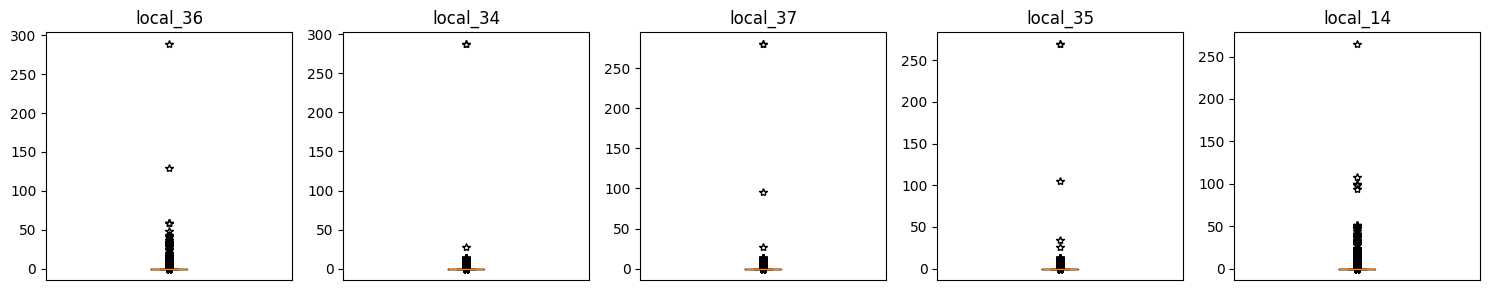

In [18]:
top_features = df[FEATURES].max().nlargest(5).index

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, column in zip(axes, top_features):
    ax.boxplot(df[column], sym="*")
    ax.set_title(column)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

IQR для выбросов здесь не подходит. У 55 признаков IQR равен 0, поэтому выбросом считается любое значение,
отличное от самого частого. Но и у остальных 110 признаков оно отмечает в среднем около 12% значений
(до 40%), потому что распределения сильно скошены. В итоге выброс находится примерно у 95% транзакций.

Дальше считаем значение экстремальным, если оно дальше 3 стандартных отклонений от среднего. Это
условное правило: стандартное отклонение тоже зависит от больших значений, поэтому оно отмечает заметно
большие значения, но не доказывает, что они ошибочны.

In [19]:
is_extreme = df[FEATURES].abs() > 3

extreme_share = is_extreme.mean()
n_extreme = is_extreme.sum(axis=1)

pd.Series({
    "признаков без экстремальных значений": (extreme_share == 0).sum(),
    "медианная доля в признаке": extreme_share.median(),
    "наибольшая доля в признаке": extreme_share.max(),
    "доля транзакций хотя бы с одним": (n_extreme >= 1).mean(),
    "доля транзакций с 20 и более": (n_extreme >= 20).mean(),
}, name="значение").round(4).to_frame()

,значение
признаков без экстремальных значений,45.0000
медианная доля в признаке,0.0078
наибольшая доля в признаке,0.0844
доля транзакций хотя бы с одним,0.3726
доля транзакций с 20 и более,0.0136


In [20]:
pd.DataFrame({
    "доля транзакций с выбросами": (n_extreme >= 1).groupby(df["label"]).mean(),
    "выбросов на транзакцию, в среднем": n_extreme.groupby(df["label"]).mean(),
    "выбросов на транзакцию, медиана": n_extreme.groupby(df["label"]).median(),
}).round(3).rename_axis("метка")

,доля транзакций с выбросами,"выбросов на транзакцию, в среднем","выбросов на транзакцию, медиана"
метка,,,
illicit,0.174,0.589,0.0
licit,0.678,5.868,3.0
unknown,0.297,1.195,0.0


In [21]:
labeled = df["y"].notna()
extreme_group = pd.cut(n_extreme[labeled], bins=[-1, 0, 4, 19, 165], labels=["0", "1–4", "5–19", "20+"])

by_group = pd.crosstab(extreme_group, df.loc[labeled, "label"], normalize="index").round(3)
by_group.index.name = "выбросов в транзакции"
by_group.insert(0, "транзакций", extreme_group.value_counts())
by_group

label,транзакций,illicit,licit
выбросов в транзакции,,,
0,17296,0.217,0.783
1–4,11939,0.050,0.950
5–19,14593,0.013,0.987
20+,2736,0.000,1.000


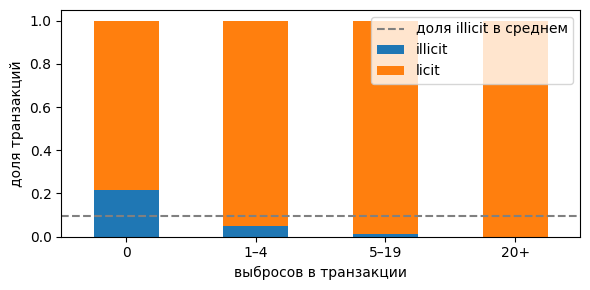

In [22]:
by_group[["illicit", "licit"]].plot.bar(stacked=True, rot=0, figsize=(6, 3))
plt.axhline(df["y"].mean(), color="gray", linestyle="--", label="доля illicit в среднем")
plt.xlabel("выбросов в транзакции")
plt.ylabel("доля транзакций")
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
df.loc[n_extreme >= 1, "label"].value_counts().rename("удалили бы строк").to_frame()

,удалили бы строк
label,
unknown,46655
licit,28479
illicit,789


**Вывод.** IQR для поиска выбросов нам не подходит. При его использовании выброс находится примерно у 95% транзакций.
По правилу 3 std в отдельном признаке экстремальных значений обычно меньше 1% (медиана 0.78%, максимум 8.44%),
а 45 признаков не содержат их совсем. Но хотя бы одно такое значение есть у 37% транзакций.

Экстремальные значения не указывают на незаконные транзакции, скорее наоборот. Хотя бы одно такое
значение есть у 67.8% `licit` и только у 17.4% `illicit`. Доля `illicit` падает с 21.7% среди транзакций
без экстремальных значений до 0% среди транзакций с 20 и более (2 736 транзакций).

**Решение.** Строки не удаляем: мы потеряли бы 37% транзакций, из них 46 655 `unknown`, 28 479 `licit`
и 789 `illicit`. Почти все удалённые размеченные транзакции оказались бы `licit`, и баланс классов
сильно исказился бы. Значения выглядят как свойство данных, а не как ошибки, поэтому
на этапе EDA оставляем их без изменений. На этапе моделей для деревьев и бустинга ничего делать
не будем, а для логистической регрессии проверим, улучшает ли качество ограничение больших значений.
Параметры ограничения подбираем только на обучающей части, чтобы не было утечки из теста.

## 5. Общие выводы

В таблице 203 769 транзакций и 165 признаков. Признаки уже нормализованы, а что они значат, неизвестно.
Пропусков в признаках нет. Пустые значения есть только в `y`: это 77.1% транзакций с меткой `unknown`,
у которых просто нет разметки.

Явных ошибок не нашли. Идентификаторы не повторяются, шаги лежат в диапазоне 1–49, классы и связи
согласованы. Есть 49 транзакций с одинаковыми признаками, но их слишком мало, чтобы на что-то повлиять.
Заметнее другое: у 76 признаков одно значение занимает больше половины строк, поэтому распределения
сильно скошены.

Выбросы тут работают интересно. Интуитивно кажется, что незаконные транзакции чаще будут выделяться большими значениями, но здесь наоборот: такие значения есть у 67.8% `licit` и только у 17.4% `illicit`. Почему так, пока не ясно. Возможно, дело в том, какие транзакции вообще попали в разметку.

Для следующего этапа это значит следующее. Пропуски заполнять и признаки нормализовать повторно не нужно.
Выбросы не будем удалять: иначе потеряем больше трети транзакций, а среди размеченных уйдут почти одни `licit`. Деревьям и бустингу отдаём
признаки как есть, а для логистической регрессии проверим, помогает ли ограничить большие значения.
Почти константные признаки уберём, только если так решит отбор признаков на обучающей части.
Обучаем модели на размеченных транзакциях, а `unknown` оставляем для semi-supervised подходов.